# TP 1 — Construire un pipeline NLP classique

**Cours NLP et Transformers — CY Tech**

---

**Nom: Alexandre Huet**

## Avant de commencer

**Faites tout de suite : `Fichier` → `Enregistrer une copie dans Drive`.**
Sans cela vous travaillez sur une copie temporaire et vous perdrez tout en fermant l'onglet.

## Objectif

Construire un pipeline de classification de texte **complet et correctement évalué**, de bout en bout :

`texte brut → prétraitement → représentation → modèle → mesure`

Le but n'est pas d'obtenir le meilleur score. Le but est que **chaque décision du pipeline soit justifiée** et que le score annoncé soit crédible.

## Ce qui est attendu

1. Un jeu de données étiqueté construit à partir du corpus brut
2. Un prétraitement et une représentation TF–IDF
3. Une **baseline** avant tout modèle
4. **Au moins deux modèles** de machine learning comparés
5. Une évaluation avec accuracy, précision, rappel, F1 et matrice de confusion
6. Une **analyse des erreurs** rédigée (partie 8) — c'est la partie la plus importante

## Les deux erreurs qui coûtent des points

- Vectoriser **avant** de découper train/test → fuite de données, tout le TP est invalidé
- Afficher une matrice de confusion sans la commenter

---

## 0. Environnement

Rien à installer : tout est déjà présent dans Colab. Exécutez simplement la cellule.

In [ ]:
import re
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environnement prêt.")

Environnement prêt.


## 1. Charger le corpus

Le corpus **Tiny Shakespeare** : environ 40 000 lignes extraites de plusieurs pièces de Shakespeare.

C'est du **texte brut, sans aucune étiquette**. C'est volontaire : une grande partie du travail d'un data scientist consiste à transformer une matière première non structurée en un problème d'apprentissage bien posé.

In [ ]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

texte = urllib.request.urlopen(URL).read().decode("utf-8")

print(f"{len(texte):,} caractères")
print(f"{len(texte.splitlines()):,} lignes")
print("\n--- 300 premiers caractères ---\n")
print(texte[:300])

1,115,394 caractères
40,000 lignes

--- 300 premiers caractères ---

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


## 2. Observer la structure avant de coder

**Avant d'écrire quoi que ce soit, regardez vos données.** C'est la première règle du métier, et c'est celle qu'on saute le plus souvent.

Affichez un extrait plus long et répondez aux questions ci-dessous.

In [ ]:
# TODO : afficher les caractères 1000 à 2500 du corpus
print(texte[1000:2500])

Second Citizen:
Would you proceed especially against Caius Marcius?

All:
Against him first: he's a very dog to the commonalty.

Second Citizen:
Consider you what services he has done for his country?

First Citizen:
Very well; and could be content to give him good
report fort, but that he pays himself with being proud.

Second Citizen:
Nay, but speak not maliciously.

First Citizen:
I say unto you, what he hath done famously, he did
it to that end: though soft-conscienced men can be
content to say it was for his country he did it to
please his mother and to be partly proud; which he
is, even till the altitude of his virtue.

Second Citizen:
What he cannot help in his nature, you account a
vice in him. You must in no way say he is covetous.

First Citizen:
If I must not, I need not be barren of accusations;
he hath faults, with surplus, to tire in repetition.
What shouts are these? The other side o' the city
is risen: why stay we prating here? to the Capitol!

All:
Come, come.

First C

**Questions — répondez ici avant de continuer :**

1. Quelle est la structure répétitive du texte ? Qu'est-ce qui sépare deux blocs ?
2. Quelle information exploitable comme étiquette est déjà présente dans le texte ?
3. Cette étiquette existait-elle vraiment, ou faut-il l'annoter à la main ?

> *Vos réponses :*
>
> 1. Chaque ligne commence avec un nom de locuteur qui est ensuite suivi de sa phrase dans le play. Deux blocs sont séparés par une ligne vide. Par exemple (Second Citizen: phrase 1, All: phrase 2, etc.).
> 2. C'est le nom du locuteur qu'on peut voir qui est deja présent avant chaque réponse dans le play. Par exemple (Second Citizen:, First Citizen:, All:, MENENIUS:)
> 3. Non cette étiquette n'a pas été ajoutée à la main pour cet exercice parce que c'est l'usage dans le formatage des pièces de theatre: donc toutes les phrases ont un nom du locuteur avant et sans qu'aucune annotation manuelle n'ait été nécessaire. En effet, c'est un très bon exemple d'apprentissage auto supervisé vu en cours.

---

💡 **Le point à retenir.** Vous venez de trouver une cible qui existait déjà dans les données, sans le moindre annotateur humain. C'est exactement le principe de l'**apprentissage auto-supervisé** vu en cours : on fabrique le signal à partir de la structure du texte lui-même. C'est le mécanisme qui rend possible l'entraînement des grands modèles de langage.

## 3. Construire le jeu de données étiqueté

La fonction de parsing vous est donnée : ce n'est pas l'objet du TP, et une regex mal réglée vous ferait perdre une heure.

**Lisez-la quand même**, vous devrez justifier ce qu'elle garde et ce qu'elle jette.

In [ ]:
def parser_repliques(txt: str) -> pd.DataFrame:
    """Découpe le corpus en répliques (locuteur, texte).

    Format attendu dans le corpus :

        NOM DU LOCUTEUR:
        première ligne de la réplique
        seconde ligne de la réplique

    Les blocs sont séparés par une ligne vide.
    """
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


df = parser_repliques(texte)

print(f"{len(df):,} répliques extraites")
print(f"{df['locuteur'].nunique()} locuteurs distincts")
df.head(10)

7,094 répliques extraites
297 locuteurs distincts


,locuteur,replique
0,First Citizen,"Before we proceed any further, hear me speak."
1,All,"Speak, speak."
2,First Citizen,You are all resolved rather to die than to fam...
3,All,Resolved. resolved.
4,First Citizen,"First, you know Caius Marcius is chief enemy t..."
5,All,"We know't, we know't."
6,First Citizen,"Let us kill him, and we'll have corn at our ow..."
7,All,"No more talking on't; let it be done: away, away!"
8,Second Citizen,"One word, good citizens."
9,First Citizen,"We are accounted poor citizens, the patricians..."


### 3.1 Explorer la distribution

Avant de choisir votre tâche, il faut savoir à quoi ressemble la distribution des classes.

locuteur
GLOUCESTER           211
DUKE VINCENTIO       189
MENENIUS             161
ROMEO                160
PETRUCHIO            155
CORIOLANUS           148
KING RICHARD III     137
ISABELLA             127
JULIET               124
LEONTES              124
SICINIUS             117
KING EDWARD IV       109
QUEEN ELIZABETH      105
LUCIO                101
WARWICK               98
KING RICHARD II       98
BRUTUS                91
HENRY BOLINGBROKE     90
TRANIO                90
BUCKINGHAM            89
Name: count, dtype: int64


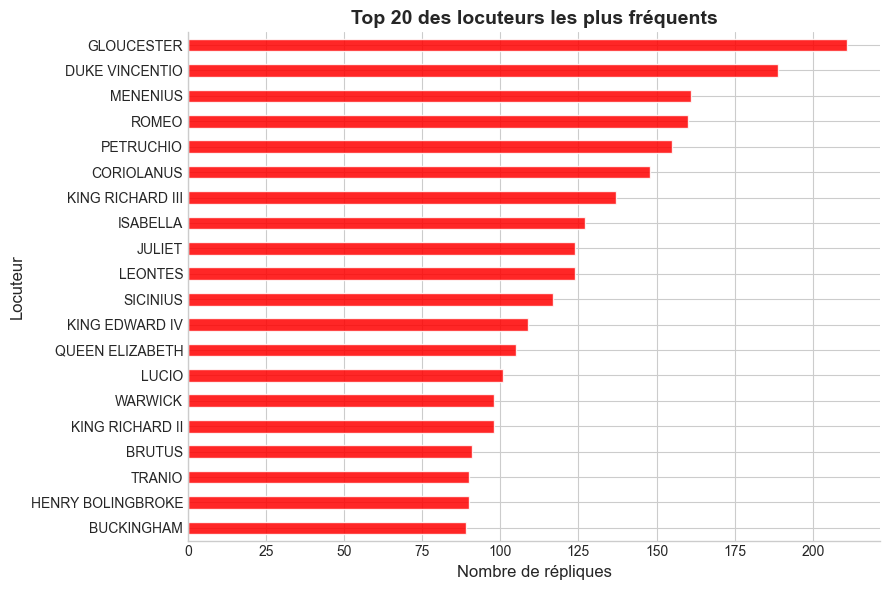

Médiane : 14.0
Moyenne : 27.17817874259938


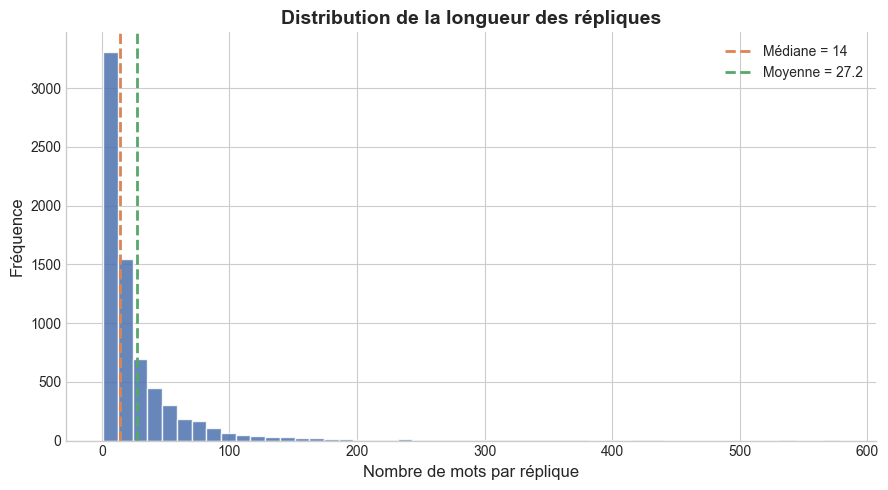

In [ ]:
# TODO : afficher les 20 locuteurs les plus fréquents et leur nombre de répliques
top20 = df['locuteur'].value_counts().head(20)
print(top20)

plt.style.use('seaborn-v0_8-whitegrid')

#top 20 locuteurs
fig, ax = plt.subplots(figsize=(9, 6))
top20.sort_values().plot(kind='barh', ax=ax, color="#FF0000", edgecolor='white', alpha=0.85)

ax.set_xlabel("Nombre de répliques", fontsize=12)
ax.set_ylabel("Locuteur", fontsize=12)
ax.set_title("Top 20 des locuteurs les plus fréquents", fontsize=14, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# TODO : afficher la distribution de la longueur des répliques (en nombre de mots)
#        -> médiane, moyenne, et un histogramme
df['n_mots'] = df['replique'].str.split().str.len()
mediane = df['n_mots'].median()
moyenne = df['n_mots'].mean()
print("Médiane :", mediane)
print("Moyenne :", moyenne)

#distribution de la longueur des répliques
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(df['n_mots'], bins=50, color='#4C72B0', edgecolor='white', alpha=0.85)

ax.axvline(mediane, color='#DD8452', linestyle='--', linewidth=2, label=f'Médiane = {mediane:.0f}')
ax.axvline(moyenne, color='#55A868', linestyle='--', linewidth=2, label=f'Moyenne = {moyenne:.1f}')

ax.set_xlabel("Nombre de mots par réplique", fontsize=12)
ax.set_ylabel("Fréquence", fontsize=12)
ax.set_title("Distribution de la longueur des répliques", fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

**Questions :**

1. La distribution des locuteurs est-elle équilibrée ? Que se passerait-il si vous gardiez les 297 locuteurs ?
2. Quelle est la longueur médiane d'une réplique ? Est-ce beaucoup pour de la classification de texte ?
3. Quelle conséquence cette longueur aura-t-elle sur votre vecteur TF–IDF ?

> *Vos réponses :*
>
> 1. Non, on peut voir dans le graphique des value_counts ci dessus que la distribution des locuteurs n'est pas équilibrée. Les 20 locuteurs plus fréquents ont beaucoup de repliques chacun. Mais la plupart des 297 locuteurs n'en ont que très peu. Si on garde les 297 locuteurs, on va avoir un problème de multiclasse où on a un très grand nombre de classes très peu représentées. En effet, cela rend l'apprentissage très difficile et empêche un split correct pour les classes ayant trop peu d'exemples.

> 2. La longueur médiane d'une réplique est de 14 mots et la moyenne de 27,2 mots. À mon avis, c'est assez court pour de la classification de texte. Donc chaque réplique contient peu de mots exploitables. On peut voir aussi que la moyenne est plus élevée que la médiane ce qui montre qu'il y a quelques répliques très longues qui tirent la moyenne vers le haut.

> 3. Les conséquences que cette longueur de répliques courtes (médiane de 14 mots) va avoir sur le vecteur TF-IDF. C'est qu'il aura très peu de valeurs non nulles. Donc peu de mots exploitables par réplique. Cela rend la matrice encore plus creuse et donne moins de signal au modèle pour distinguer les locuteurs.

## 4. Définir la tâche

À vous de poser le problème. Vous devez décider :

- **combien de locuteurs** vous gardez (le nombre de classes) ;
- s'il faut **filtrer les répliques trop courtes**, et à partir de quel seuil ;
- si vos classes sont suffisamment **équilibrées** pour que l'accuracy ait un sens.

Il n'y a pas une seule bonne réponse. Il y a des choix, et ils doivent être **justifiés et écrits**.

> **Votre choix et sa justification :**
>
> - Nombre de locuteurs retenus :
> - Seuil de longueur minimale :
> - Pourquoi :

In [ ]:
# TODO : construire `donnees`, un DataFrame filtré contenant :
#          - colonne 'replique' : le texte
#          - colonne 'locuteur' : l'étiquette
#
# Contraintes :
#   - ne garder que les N locuteurs les plus fréquents (choisissez N)
#   - écarter les répliques trop courtes (choisissez le seuil)

N = 5
SEUIL_LONGUEUR = 5

top_speakers = df['locuteur'].value_counts().head(N).index.tolist()

donnees = df[
    df['locuteur'].isin(top_speakers) &
    (df['n_mots'] >= SEUIL_LONGUEUR)
][['replique', 'locuteur']].reset_index(drop=True)

print(donnees['locuteur'].value_counts())
print(f"\n{len(donnees)} exemples retenus")

locuteur
GLOUCESTER        196
DUKE VINCENTIO    165
ROMEO             141
PETRUCHIO         133
MENENIUS          126
Name: count, dtype: int64

761 exemples retenus


- Nombre de locuteurs retenus: 5

- Seuil de longueur minimale: 5 mots

- Pourquoi: J'ai choisi de garder les 5 locuteurs les plus fréquents (GLOUCESTER, DUKE VINCENTIO, ROMEO, PETRUCHIO, MENENIUS) car après filtrage. Ils ont un nombre de répliques assez proche (entre 126 et 196) est donc donne des classes relativement équilibrées avec 761 exemples au total. J'ai fixé le seuil de longueur à 5 mots pour écarter les répliques trop courtes qui contiennent peu de vocabulaire exploitable sans être trop strict par rapport à la médiane de 14 mots observée en dernier exercise.

## 5. ⚠️ Découper AVANT toute transformation

**C'est le point le plus important du TP.**

Tout composant qui **apprend quelque chose à partir des données** doit être ajusté sur le train seulement :

| Composant | Ce qu'il apprend en regardant les données |
|---|---|
| Vocabulaire TF–IDF | quels mots existent, et quelle colonne chacun occupe |
| Poids IDF | dans combien de documents chaque mot apparaît |
| Normalisation | la moyenne et l'écart-type de chaque variable |

Si vous vectorisez avant de découper, les fréquences du test participent au calcul de l'IDF. Votre modèle a alors utilisé une information issue du test : **votre score final sera surestimé et ne voudra plus rien dire.**

La discipline tient en deux lignes :

```python
X_train = vectorizer.fit_transform(train)   # fit + transform
X_test  = vectorizer.transform(test)        # transform SEULEMENT
```

Pensez à **stratifier** le découpage : sans cela, un locuteur peu représenté peut être absent du test.

In [ ]:
# TODO : découper en train / test
#   - 20 % pour le test
#   - stratifier sur le locuteur
#   - random_state=RANDOM_STATE pour que vos résultats soient reproductibles

X_train, X_test, y_train, y_test = train_test_split(
    donnees['replique'], donnees['locuteur'],
    test_size=0.2,
    stratify=donnees['locuteur'],
    random_state=RANDOM_STATE,
)

print(f"train: {len(X_train)} exemples")
print(f"test : {len(X_test)} exemples")

train: 608 exemples
test : 153 exemples


## 6. Représenter le texte

Vous allez transformer chaque réplique en vecteur TF–IDF.

`TfidfVectorizer` expose plusieurs paramètres qui sont autant de décisions de prétraitement. Regardez au moins ceux-ci et **choisissez consciemment** :

| Paramètre | Question qu'il pose |
|---|---|
| `lowercase` | la casse porte-t-elle du signal pour votre tâche ? |
| `ngram_range` | faut-il récupérer un peu d'ordre local avec des bigrammes ? |
| `min_df` | à partir de combien d'occurrences un mot mérite-t-il une colonne ? |
| `max_df` | faut-il écarter les mots omniprésents ? |
| `stop_words` | ⚠️ attention au piège vu en cours |
| `sublinear_tf` | 10 occurrences valent-elles vraiment 10 fois 1 occurrence ? |

> **Vos choix et leur justification :**

In [ ]:
# TODO : instancier le vectoriseur, l'ajuster sur le train, transformer les deux jeux

vectoriseur = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.9,
    stop_words=None,
    sublinear_tf=True,
)

Xtr = vectoriseur.fit_transform(X_train)
Xte = vectoriseur.transform(X_test)

print(f"Taille du vocabulaire: {len(vectoriseur.vocabulary_):,}")
print(f"Matrice train: {Xtr.shape}")
print(f"Sparsité: {Xtr.nnz / (Xtr.shape[0] * Xtr.shape[1]):.4%} de valeurs non nulles")

Taille du vocabulaire: 3,464
Matrice train: (608, 3464)
Sparsité: 0.9716% de valeurs non nulles


J'ai choisi d'utiliser lowercase=True parce que la casse ne porte pas de signal utile pour distinguer les locuteurs. Ensuite, j'ai utilisé ngram_range=(1,2) pour savoir et récupérer un peu d'ordre local avec les bigrammes et en plus des mots seuls. Apres, j'ai fixé min_df=2 pour écarter les mots qui n'apparaissent qu'une seule fois car ils sont peu fiables pour généraliser. J'ai aussi gardé le max_df à 0.9 pour écarter les mots peu informatifs. De plus, j'ai laissé stop_words=None car les pronoms et mots fonctionnels peuvent porter le style propre d'un personnage comme vu en cours avec le piège des stopwords. Enfin, sublinear_tf=True évite qu'un mot répété plusieurs fois dans une réplique pèse trop.

**Questions :**

1. Quelle proportion de votre matrice est constituée de zéros ? Pourquoi est-ce structurellement inévitable ?
2. Que se passerait-il si vous stockiez cette matrice en tableau NumPy dense ?
3. Affichez les 15 termes ayant le poids IDF le plus élevé, puis les 15 plus faibles. Le résultat vous surprend-il ?

> *Vos réponses :*
>
> 1. On peut voir dans le résultat que seulement 0,9716% des valeurs sont non nulles. Donc environ 99% de la matrice est constituée de zéros. C'est inévitable parce que chaque réplique est courte (médiane de 14 mots) et n'utilise donc qu'une petite partie des 3464 mots du vocabulaire.

> 2. J'ai remarqué qu'un tableau dense stockerait toutes les 608 × 3464 valeurs y compris les zéros ce qui prendrait beaucoup plus de mémoire. Le format creux ne stocke que les valeurs non nulles.

> 3. Non, ça ne me surprend pas du tout. On peut voir que les 15 termes avec l'IDF le plus faible sont des mots très communs. (and, the, to, you, of, etc.) À l'inverse, les termes avec l'IDF le plus élevé sont des bigrammes rares, par exemple ("your sister", "you villains") qui n'apparaissent que dans très peu de répliques. C'est exactement ce que l'IDF est censé faire donc ça ne me surprend pas.

In [ ]:
# TODO : afficher les 15 termes de plus fort et de plus faible IDF
#        (indice : vectoriseur.idf_ et vectoriseur.get_feature_names_out())

idf_scores = pd.Series(vectoriseur.idf_, index=vectoriseur.get_feature_names_out())

print("IDF les plus élevés:")
print(idf_scores.sort_values(ascending=False).head(15))

print("\nIDF les plus faibles:")
print(idf_scores.sort_values().head(15))


IDF les plus élevés:
your sister     6.313206
able            6.313206
you then        6.313206
you villains    6.313206
you please      6.313206
you should      6.313206
you miss        6.313206
you only        6.313206
you lie         6.313206
you like        6.313206
you little      6.313206
you look        6.313206
you make        6.313206
although        6.313206
am an           6.313206
dtype: float64

IDF les plus faibles:
and     1.718086
the     1.741937
to      1.817107
you     1.982473
of      2.088808
that    2.175376
is      2.247032
in      2.293824
not     2.324222
my      2.355572
for     2.361962
me      2.394538
it      2.470176
with    2.491837
this    2.499163
dtype: float64


## 7. Modéliser

### 7.1 D'abord la baseline — sans exception

Une baseline vous donne le **plancher** : le score qu'on atteint sans rien apprendre.

Sans elle, vous ne pouvez pas savoir si 65 % est un bon résultat ou un résultat catastrophique. C'est un réflexe professionnel, pas une formalité pédagogique.

In [ ]:
# TODO : entraîner un DummyClassifier (strategy='most_frequent' puis 'stratified')
#        et afficher son accuracy et son F1 macro sur le test
for strat in ['most_frequent', 'stratified']:
    dummy = DummyClassifier(strategy=strat, random_state=RANDOM_STATE)
    dummy.fit(Xtr, y_train)
    preds = dummy.predict(Xte)
    print(strat,
          "accuracy:", accuracy_score(y_test, preds),
          "F1 macro:", f1_score(y_test, preds, average='macro'))

most_frequent accuracy: 0.26143790849673204 F1 macro: 0.08290155440414507
stratified accuracy: 0.19607843137254902 F1 macro: 0.18892605334539964


> **Score de la baseline :**
>
>Le score de la baseline (DummyClassifier) est de 26,1% d'accuracy et 0,083 de F1 macro pour la stratégie most_frequent, et 19,6% d'accuracy et 0,189 de F1 macro pour la stratégie stratified.

> Tout modèle qui ne dépasse pas nettement ce score n'apprend rien d'utile.

### 7.2 Au moins deux modèles

Choisissez-en au moins deux parmi : `MultinomialNB`, `LogisticRegression`, `LinearSVC`.

Pour chacun, notez **pourquoi** il est adapté (ou non) à une représentation TF–IDF très creuse et de grande dimension.

⚠️ Vos classes sont probablement déséquilibrées. Regardez ce que fait `class_weight='balanced'` et dites si vous le gardez.

In [ ]:
# TODO : entraîner au moins deux modèles et stocker leurs prédictions
#        Suggestion : un dictionnaire {nom_du_modele: predictions}

resultats = {}

for nom, clf in [
    ("NaiveBayes", MultinomialNB()),
    ("LogReg", LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)),
    ("LinearSVC", LinearSVC(class_weight='balanced', random_state=RANDOM_STATE)),
]:
    clf.fit(Xtr, y_train)
    resultats[nom] = clf.predict(Xte)

print(resultats.keys())


dict_keys(['NaiveBayes', 'LogReg', 'LinearSVC'])


J'ai choisi d'entraîner trois modèles: Naive Bayes, régression logistique et LinearSVC.

- **Naive Bayes:** est très rapide et fonctionne bien sur des comptages creux comme le TF–IDF mais il suppose que les mots sont indépendants les uns des autres ce qui n'est pas réaliste.
- **La régression logistique:** est un modèle linéaire adapté à la grande dimension creuse du TF–IDF et donne des coefficients interprétables par classe.
- **LinearSVC:** est souvent le plus performant sur du texte en grande dimension car il cherche une séparation à grande marge mais il ne donne pas de probabilités directement.

J'ai gardé `class_weight='balanced'` pour la régression logistique et LinearSVC car mes classes ne sont pas parfaitement équilibrées (entre 126 et 196 exemples) et ce paramètre permet de mieux traiter les classes minoritaires plutôt que de favoriser les classes les plus fréquentes.

## 8. Évaluer et analyser

### 8.1 Les métriques

Rappel du cours : sur des classes déséquilibrées, **l'accuracy ment**. Reportez toujours le F1, et précisez la méthode d'agrégation.

- `average='macro'` : moyenne non pondérée sur les classes → traite les classes rares à égalité
- `average='weighted'` : pondérée par les effectifs → dominée par les classes fréquentes

Indiquez explicitement laquelle vous utilisez et pourquoi.

In [ ]:
#Pas important
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

# TODO : pour chaque modèle, afficher accuracy, précision, rappel et F1 (macro et weighted)
#        puis un classification_report complet
#        Présentez la comparaison sous forme de tableau (DataFrame)

#baseline
dummy = DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE)
dummy.fit(Xtr, y_train)
resultats_avec_baseline = {"Baseline": dummy.predict(Xte), **resultats}

rows = []
for nom, preds in resultats_avec_baseline.items():
    rows.append({
        "modèle": nom,
        "accuracy": accuracy_score(y_test, preds),
        "précision_macro": precision_score(y_test, preds, average='macro'),
        "rappel_macro": recall_score(y_test, preds, average='macro'),
        "F1_macro": f1_score(y_test, preds, average='macro'),
        "F1_weighted": f1_score(y_test, preds, average='weighted'),
    })
    print(f"\n {nom} ")
    print(classification_report(y_test, preds))

pd.DataFrame(rows)


 Baseline 
                precision    recall  f1-score   support

DUKE VINCENTIO       0.00      0.00      0.00        33
    GLOUCESTER       0.26      1.00      0.41        40
      MENENIUS       0.00      0.00      0.00        25
     PETRUCHIO       0.00      0.00      0.00        27
         ROMEO       0.00      0.00      0.00        28

      accuracy                           0.26       153
     macro avg       0.05      0.20      0.08       153
  weighted avg       0.07      0.26      0.11       153


 NaiveBayes 
                precision    recall  f1-score   support

DUKE VINCENTIO       0.60      0.76      0.67        33
    GLOUCESTER       0.42      0.88      0.57        40
      MENENIUS       1.00      0.28      0.44        25
     PETRUCHIO       1.00      0.37      0.54        27
         ROMEO       0.82      0.32      0.46        28

      accuracy                           0.56       153
     macro avg       0.77      0.52      0.54       153
  weighted avg   

,modèle,accuracy,précision_macro,rappel_macro,F1_macro,F1_weighted
0,Baseline,0.261438,0.052288,0.200000,0.082902,0.108368
1,NaiveBayes,0.562092,0.767021,0.520875,0.535070,0.543918
2,LogReg,0.666667,0.670653,0.668974,0.667770,0.667421
3,LinearSVC,0.647059,0.652305,0.649484,0.648625,0.646704


LogReg obtient les meilleurs résultats : accuracy de 66.7%, F1 macro de 0.668 et F1 weighted de 0.667. LinearSVC est un peu en dessous (F1 macro = 0.649). NaiveBayes a la meilleure précision macro (0,767) mais le plus faible rappel macro (0.521) ce qui donne un F1 macro bien plus bas aussi (0.535).

### 8.2 La matrice de confusion

Affichez-la pour votre meilleur modèle. **Une matrice affichée sans commentaire ne vaut rien** — c'est la partie 8.3 qui compte.

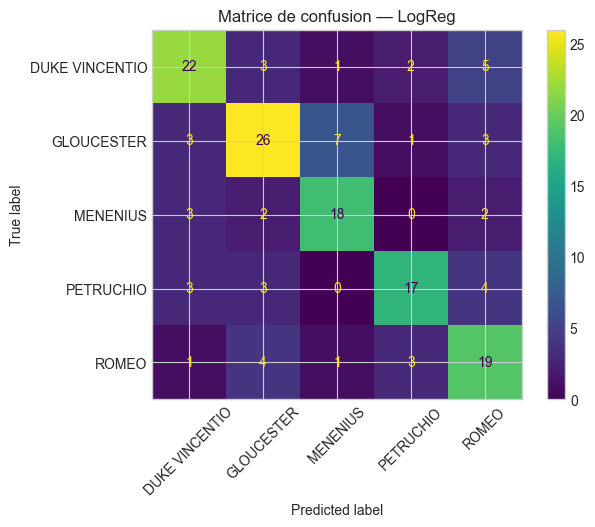

In [ ]:
# TODO : afficher la matrice de confusion du meilleur modèle
#        (indice : ConfusionMatrixDisplay.from_predictions)
meilleur_modele = "LogReg"
ConfusionMatrixDisplay.from_predictions(
    y_test, resultats[meilleur_modele], xticks_rotation=45
)
plt.title(f"Matrice de confusion — {meilleur_modele}")
plt.show()

Q1 Code

In [ ]:
mask_erreurs = resultats[meilleur_modele] != y_test.values
df_erreurs = pd.DataFrame({
    "texte": X_test.values[mask_erreurs],
    "vrai": y_test.values[mask_erreurs],
    "prédit": resultats[meilleur_modele][mask_erreurs],
})

from collections import Counter
paires = Counter(zip(df_erreurs['vrai'], df_erreurs['prédit']))
print(paires.most_common(5))

[(('GLOUCESTER', 'MENENIUS'), 7), (('DUKE VINCENTIO', 'ROMEO'), 5), (('PETRUCHIO', 'ROMEO'), 4), (('ROMEO', 'GLOUCESTER'), 4), (('ROMEO', 'PETRUCHIO'), 3)]


Q2 Code

In [ ]:
print(df_erreurs.sample(5, random_state=RANDOM_STATE))

                                                texte        vrai  \
43  Now, my Lord Hastings and Sir William Stanley,...  GLOUCESTER   
40  What then? 'Fore me, this fellow speaks! What ...    MENENIUS   
46           Let me stand here till thou remember it.       ROMEO   
12  O, pardon me, Signior Gremio; I would fain be ...   PETRUCHIO   
24  O monstrous arrogance! Thou liest, thou thread...   PETRUCHIO   

            prédit  
43  DUKE VINCENTIO  
40           ROMEO  
46       PETRUCHIO  
12      GLOUCESTER  
24           ROMEO  


Q3 Code

In [ ]:
log_reg = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)
log_reg.fit(Xtr, y_train)

feature_names = vectoriseur.get_feature_names_out()
for i, classe in enumerate(log_reg.classes_):
    top_idx = log_reg.coef_[i].argsort()[-10:][::-1]
    print(classe, "->", [feature_names[j] for j in top_idx])

DUKE VINCENTIO -> ['you', 'angelo', 'him', 'duke', 'provost', 'your', 'claudio', 'the duke', 'to', 'sir']
GLOUCESTER -> ['king', 'clarence', 'lord', 'edward', 'my lord', 'cousin', 'god', 'warwick', 'the king', 'brother']
MENENIUS -> ['he', 'you', 'marcius', 'like', 'rome', 'you have', 'tribunes', 'pray', 'general', 'the']
PETRUCHIO -> ['kate', 'hortensio', 'come', 'and', 'sir', 'her', 'why', 'not', 'me', 'she']
ROMEO -> ['love', 'thy', 'thou', 'mercutio', 'goose', 'night', 'what shall', 'dream', 'wilt', 'light']


### 8.3 Analyse des erreurs — la partie la plus importante

Répondez précisément, en vous appuyant sur des exemples concrets tirés de vos données.

1. **Quelles paires de locuteurs sont le plus confondues ?** Formulez une hypothèse : viennent-ils de la même pièce ? ont-ils un registre proche ? un nombre d'exemples très différent ?

2. **Sortez cinq répliques mal classées et lisez-les.** Auriez-vous su répondre vous-même ? Si non, que dit cela sur le plafond de performance atteignable ?

3. **Regardez les coefficients de votre modèle linéaire** (`coef_`) : quels termes pèsent le plus pour chaque classe ? Y a-t-il des **noms propres** parmi eux ?

   Si oui, posez-vous la vraie question : votre modèle reconnaît-il le **style d'un personnage**, ou identifie-t-il simplement la **pièce** dans laquelle la réplique apparaît ? Ce n'est pas du tout la même tâche, et cela change ce que vous pouvez affirmer sur votre modèle.

4. **Votre score est-il crédible ?** Reprenez votre pipeline et vérifiez qu'aucune information du test n'a pu remonter vers l'entraînement.

> *Votre analyse :*
>
> 1. La paire la plus confondue est GLOUCESTER prédit comme MENENIUS (7 erreurs). Une hypothèse possible est que ces deux personnages ont un registre de langage proche ou peut être que le modèle se base sur des mots communs plutôt que sur un vocabulaire vraiment distinctif de chaque personnage.

> 2. Certaines répliques mal classées sont très courtes et génériques. Par exemple "Let me stand here till thou remember it.", donc je n'aurais probablement pas su deviner le locuteur moi même. Cela montre qu'il y a un plafond de performance atteignable. D'autres erreurs contiennent des noms propres comme ("Signior Gremio") qu'un humain pourrait utiliser pour deviner correctement. Mais le modèle ne les exploite pas toujours bien.

> 3. On peut voir dans le résultat du code Q3 ci dessus que oui, la plupart des mots les plus importants sont des noms propres d'autres personnages. Par exemple: (angelo, claudio, clarence, edward, warwick, marcius, kate, hortensio, mercutio). Cela montre que le modèle identifie surtout la pièce dans laquelle la réplique apparaît plutôt que le style propre de chaque personnage. Seul ROMEO a quelques mots plus liés au style (love, thy, thou, dream) en plus du nom propre "mercutio".

> 4. On peut voir en reprenant le pipeline que le split train/test a été fait avant toute vectorisation. Et j'ai aussi vérifié que le vectoriseur a été ajusté (fit_transform) uniquement sur le train puis appliqué (transform) sur le test. Les modèles ont ensuite été entraînés uniquement sur les données de train. Aucune information du test n'a donc pu remonter vers l'entraînement ce qui rend le score crédible.

## 9. Pour aller plus loin (optionnel)

Si vous avez terminé :

- **Validation croisée.** Remplacez le simple découpage par un `cross_val_score` en 5 folds sur le train. Regardez la **dispersion** des scores, pas seulement la moyenne. Un modèle à 0,82 ± 0,01 vaut souvent mieux qu'un modèle à 0,84 ± 0,09.

- **Comparer les représentations.** `CountVectorizer` (Bag of Words) contre `TfidfVectorizer`. L'écart est-il significatif ? Correspond-il à ce que le cours laissait prévoir ?

- **Faire varier la difficulté.** Passez de 5 à 10 locuteurs. Comment évoluent l'accuracy et le F1 macro ? Lequel des deux chute le plus, et pourquoi ?

- **Sur-apprentissage.** Comparez votre score sur le train et sur le test. L'écart vous dit-il quelque chose ? Que se passe-t-il quand vous faites varier `C` dans la régression logistique ?

- **Utiliser un `Pipeline` scikit-learn.** Encapsulez vectoriseur et modèle dans un `sklearn.pipeline.Pipeline`. Expliquez en une phrase pourquoi cette construction rend la fuite de données structurellement impossible.


### 1. Cross-validation:

In [ ]:
scores = cross_val_score(
    LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    Xtr, y_train, cv=5, scoring='f1_macro'
)
#cross validation en 5 folds
print("Scores par fold:", scores)
print(f"Moyenne: {scores.mean():.3f} ± {scores.std():.3f}")

Scores par fold: [0.63835915 0.61310334 0.58140864 0.54583561 0.60001932]
Moyenne: 0.596 ± 0.031


Les scores varient peu d'un fold à l'autre, ce qui montre que le modèle est stable.

### 2. BoW vs TF-IDF:

In [ ]:
#Bag of Words
count_vectoriseur = CountVectorizer(lowercase=True, ngram_range=(1,2), min_df=2, max_df=0.9)
Xtr_bow = count_vectoriseur.fit_transform(X_train)
Xte_bow = count_vectoriseur.transform(X_test)

#Modele sur BoW
clf_bow = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)
clf_bow.fit(Xtr_bow, y_train)
preds_bow = clf_bow.predict(Xte_bow)

#Comparaison entre les deux
print("BoW F1 macro:", f1_score(y_test, preds_bow, average='macro'))
print("TF-IDF F1 macro (LogReg):", f1_score(y_test, resultats['LogReg'], average='macro'))

BoW F1 macro: 0.5863904521321942
TF-IDF F1 macro (LogReg): 0.6677696511139134


L'écart entre BoW et TF-IDF est faible, ce qui correspond à ce que le cours laissait prévoir.

### 3. Faire varier la difficulté

In [ ]:
#plus de locuteurs
N2 = 10
top_speakers_10 = df['locuteur'].value_counts().head(N2).index.tolist()

donnees_10 = df[
    df['locuteur'].isin(top_speakers_10) &
    (df['n_mots'] >= SEUIL_LONGUEUR)
][['replique', 'locuteur']].reset_index(drop=True)

#Meme split avec meme vectoriseur et meme modele
X_train_10, X_test_10, y_train_10, y_test_10 = train_test_split(
    donnees_10['replique'], donnees_10['locuteur'],
    test_size=0.2, stratify=donnees_10['locuteur'], random_state=RANDOM_STATE
)

vect_10 = TfidfVectorizer(lowercase=True, ngram_range=(1,2), min_df=2, max_df=0.9, sublinear_tf=True)
#fit sur train
Xtr_10 = vect_10.fit_transform(X_train_10)
#transform sur test
Xte_10 = vect_10.transform(X_test_10)

clf_10 = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)
clf_10.fit(Xtr_10, y_train_10)
preds_10 = clf_10.predict(Xte_10)

#Comparaison entre 5 et 10 locuteurs
print("10 locuteurs - accuracy :", accuracy_score(y_test_10, preds_10))
print("10 locuteurs - F1 macro :", f1_score(y_test_10, preds_10, average='macro'))
print("5 locuteurs - accuracy :", accuracy_score(y_test, resultats['LogReg']))
print("5 locuteurs - F1 macro :", f1_score(y_test, resultats['LogReg'], average='macro'))

10 locuteurs - accuracy : 0.4389312977099237
10 locuteurs - F1 macro : 0.41836171485441637
5 locuteurs - accuracy : 0.6666666666666666
5 locuteurs - F1 macro : 0.6677696511139134


On peut voir qu'avec 10 locuteurs, l'accuracy et le F1 macro baissent tous les deux mais le F1 macro chute plus car les nouvelles classes ont moins d'exemples.

### 4. Sur apprentissage

In [ ]:
#Score train vs test
log_reg_check = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)
log_reg_check.fit(Xtr, y_train)

print("Score train :", log_reg_check.score(Xtr, y_train))
print("Score test  :", log_reg_check.score(Xte, y_test))

#Variation de C
for C in [0.01, 0.1, 1, 10, 100]:
    clf_c = LogisticRegression(C=C, max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)
    clf_c.fit(Xtr, y_train)
    print(f"C={C} -> train: {clf_c.score(Xtr, y_train):.3f}, test: {clf_c.score(Xte, y_test):.3f}")

Score train : 0.9851973684210527
Score test  : 0.6666666666666666
C=0.01 -> train: 0.929, test: 0.601
C=0.1 -> train: 0.938, test: 0.614
C=1 -> train: 0.985, test: 0.667
C=10 -> train: 1.000, test: 0.660
C=100 -> train: 1.000, test: 0.654


Le score train est plus élevé que le score test et l'écart augmente quand C devient grand, ce qui montre du sur apprentissage.

### 5. Pipeline scikit-learn

In [ ]:
from sklearn.pipeline import Pipeline

#Vectoriseur + modele dans un seul objet
pipe = Pipeline([
    ('tfidf', TfidfVectorizer(lowercase=True, ngram_range=(1,2), min_df=2, max_df=0.9, sublinear_tf=True)),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)),
])
#fit sur train seulement
pipe.fit(X_train, y_train)
#predict sur test
preds_pipe = pipe.predict(X_test)
print("Pipeline F1 macro :", f1_score(y_test, preds_pipe, average='macro'))

Pipeline F1 macro : 0.6677696511139134


Le Pipeline rend la fuite de données impossible car fit() n'est appliqué qu'aux données passées en entraînement jamais au test.